Epoch [1/10], Loss: 1.4070
Epoch [2/10], Loss: 1.1422
Epoch [3/10], Loss: 1.0346
Epoch [4/10], Loss: 0.9635
Epoch [5/10], Loss: 0.9112
Epoch [6/10], Loss: 0.8634
Epoch [7/10], Loss: 0.8246
Epoch [8/10], Loss: 0.7924
Epoch [9/10], Loss: 0.7654
Epoch [10/10], Loss: 0.7425


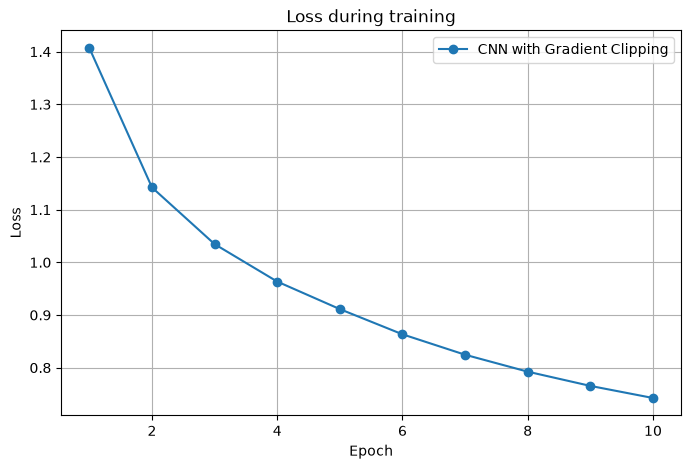

Навчання завершено!


In [1]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# 1. Пристрій
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# 2. Дані
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.4465),
    )
])

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

# 3. Архітектура CNN
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.pool = nn.MaxPool2d(2)

        self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool(self.dropout(self.relu(self.bn1(self.conv1(x)))))
        x = self.pool(self.dropout(self.relu(self.bn2(self.conv2(x)))))
        x = self.pool(self.dropout(self.relu(self.bn3(self.conv3(x)))))

        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)

        return self.fc(x)


# 4. Модель та оптимізатор
model = CNN().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# 5. Навчання з Gradient Clipping
epochs = 10

loss_history = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        # Обрізка градієнтів
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_dataset)

    loss_history.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1}/{epochs}], "
        f"Loss: {epoch_loss:.4f}"
    )


# 6. Графік зміни втрат
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    loss_history,
    marker='o',
    label='CNN with Gradient Clipping'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss during training")

plt.legend()
plt.grid(True)

plt.savefig("task2_loss.png", dpi=300)
plt.show()

print("Навчання завершено!")
